# Exploratory data analysis — MIT-BIH Arrhythmia Database
**D7043E Advanced Data Mining** · Luleå University of Technology

This notebook makes every figure and table used in sections 2 and 3 of the Task 1 report.
Figures are saved in `results/figures/` and tables in `results/`.

**Before running:** `python src/prepare_data.py --config configs/data.yaml --download`

**Rule we follow:** we *describe* all records, but every *decision* (normalisation, examples, the leakage test)
uses only DS1 (training + validation records). The test records (DS2) never influence a choice.

## Setup
Imports, settings and a few helper functions used throughout the notebook.

In [1]:
import json
import os
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import wfdb
import yaml

# run from the project root, also when the notebook is opened inside notebooks/
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, "src")

from prepare_data import (BEAT_SYMBOLS, amplitude_reference, bandpass, load_config,
                          process_signal, read_record, symbol_to_class)
from ecg_noise import add_noise, load_noise, noise_power, signal_power
from dataset import add_baseline_wander, add_gaussian_noise, scale_amplitude, shift_in_time

cfg = load_config("configs/data.yaml")
noise_cfg = yaml.safe_load(open("configs/noise.yaml"))
MITDB = cfg["paths"]["mitdb"]
NSTDB = cfg["paths"]["nstdb"]
RESULTS = cfg["paths"]["results"]
FIGURES = os.path.join(RESULTS, "figures")
os.makedirs(FIGURES, exist_ok=True)

CLASSES = cfg["classes"]                 # ['N', 'S', 'V', 'F']
SYMBOL_TO_CLASS = symbol_to_class(cfg)   # e.g. 'A' -> 1 (S)

# which split each record belongs to
SPLIT_OF = {}
for split in ("train", "val", "test"):
    for record in cfg["records"][split]:
        SPLIT_OF[record] = split
for record in cfg["records"]["excluded_paced"]:
    SPLIT_OF[record] = "paced (excluded)"

ALL_RECORDS = sorted(SPLIT_OF)                                               # all 48
USED_RECORDS = sorted(cfg["records"]["train"] + cfg["records"]["val"] + cfg["records"]["test"])  # 44
DS1_RECORDS = sorted(cfg["records"]["train"] + cfg["records"]["val"])        # 22

# colours: one per class, three shades of blue for train / validation / test
CLASS_COLOR = {"N": "#2a78d6", "S": "#eb6834", "V": "#1baf7a", "F": "#eda100"}
SPLIT_COLOR = {"train": "#86b6ef", "val": "#2a78d6", "test": "#104281"}
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#d9d8d4"
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
                     "font.size": 9, "axes.titlesize": 10, "axes.grid": True, "grid.color": GRID,
                     "grid.linewidth": 0.6, "axes.axisbelow": True, "axes.edgecolor": MUTED,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "xtick.color": MUTED, "ytick.color": MUTED, "legend.frameon": False})


def save_figure(fig, name):
    fig.savefig(os.path.join(FIGURES, name))
    plt.show()


_record_cache = {}


def load_record(record):
    # read a record and its annotations once and keep them in memory
    if record not in _record_cache:
        path = f"{MITDB}/{record}"
        _record_cache[record] = (wfdb.rdrecord(path), wfdb.rdann(path, "atr"))
    return _record_cache[record]


def beat_positions(samples, symbols):
    # positions of all annotations that are heartbeats
    return samples[np.isin(symbols, list(BEAT_SYMBOLS))]


def noisy_intervals(record):
    # Time intervals where the experts marked the MLII channel as noisy.
    # In MIT-BIH, a '~' annotation starts a new signal-quality state. Its 'subtype' tells
    # which channels are noisy: bit k set = channel k noisy, -1 = all unreadable, 0 = clean.
    # Returns a list of (start_sample, end_sample, 'noisy' or 'unreadable').
    rec, ann = load_record(record)
    mlii = rec.sig_name.index("MLII")
    intervals = []
    inside, start, unreadable = False, None, False
    for position, symbol, subtype in zip(ann.sample, ann.symbol, ann.subtype):
        if symbol != "~":
            continue
        noisy = subtype == -1 or bool(subtype & (1 << mlii))
        if noisy and not inside:
            inside, start, unreadable = True, position, subtype == -1
        elif noisy and inside:
            unreadable = unreadable or subtype == -1
        elif not noisy and inside:
            intervals.append((start, position, "unreadable" if unreadable else "noisy"))
            inside = False
    if inside:
        intervals.append((start, rec.sig_len, "unreadable" if unreadable else "noisy"))
    return intervals


print(len(ALL_RECORDS), "records in the database,", len(USED_RECORDS), "used (DS1 + DS2)")

48 records in the database, 44 used (DS1 + DS2)


## 2.1 Dataset description
One row per record: sampling rate, length, which lead is in which channel, and how many annotations it has.

In [2]:
rows = []
for record in ALL_RECORDS:
    rec, ann = load_record(record)
    symbols = np.array(ann.symbol)
    age, sex = rec.comments[0].split()[:2]
    rows.append({
        "record": record,
        "split": SPLIT_OF[record],
        "fs": rec.fs,
        "n_samples": rec.sig_len,
        "duration_min": round(rec.sig_len / rec.fs / 60, 2),
        "ch0": rec.sig_name[0],
        "ch1": rec.sig_name[1],
        "mlii_channel": rec.sig_name.index("MLII") if "MLII" in rec.sig_name else -1,
        "adc_resolution_bits": rec.adc_res[0],
        "adc_gain_per_mV": rec.adc_gain[0],
        "age": age,
        "sex": sex,
        "n_annotations": len(symbols),
        "n_beat_annotations": int(np.isin(symbols, list(BEAT_SYMBOLS)).sum()),
    })
record_info = pd.DataFrame(rows)
record_info.to_csv(f"{RESULTS}/record_info.csv", index=False)

used = record_info[record_info.split != "paced (excluded)"]
summary = {
    "records": len(record_info),
    "subjects (201 & 202 same person)": len(record_info) - 1,
    "sampling frequency (Hz)": sorted(record_info.fs.unique().tolist()),
    "samples per record": sorted(record_info.n_samples.unique().tolist()),
    "duration per record (min)": round(record_info.duration_min.mean(), 2),
    "total duration (h)": round(record_info.duration_min.sum() / 60, 2),
    "ADC resolution (bits)": sorted(record_info.adc_resolution_bits.unique().tolist()),
    "ADC gain (units/mV)": sorted(record_info.adc_gain_per_mV.unique().tolist()),
    "total annotations": int(record_info.n_annotations.sum()),
    "beat annotations (all 48 records)": int(record_info.n_beat_annotations.sum()),
    "beat annotations (44 used records)": int(used.n_beat_annotations.sum()),
    "records with MLII in channel 0": int((record_info.mlii_channel == 0).sum()),
    "records with MLII in channel 1": record_info[record_info.mlii_channel == 1].record.tolist(),
    "records without MLII": record_info[record_info.mlii_channel == -1].record.tolist(),
    "lead occurrences": pd.concat([record_info.ch0, record_info.ch1]).value_counts().to_dict(),
}
with open(f"{RESULTS}/dataset_summary.json", "w") as f:
    json.dump(summary, f, indent=2, default=int)
for key, value in summary.items():
    print(f"{key:40s} {value}")

records                                  48
subjects (201 & 202 same person)         47
sampling frequency (Hz)                  [360]
samples per record                       [650000]
duration per record (min)                30.09
total duration (h)                       24.07
ADC resolution (bits)                    [11]
ADC gain (units/mV)                      [200.0]
total annotations                        112647
beat annotations (all 48 records)        109494
beat annotations (44 used records)       100733
records with MLII in channel 0           45
records with MLII in channel 1           [114]
records without MLII                     [102, 104]
lead occurrences                         {'MLII': 46, 'V1': 40, 'V5': 5, 'V2': 4, 'V4': 1}


## Figure: example ECG signal
Ten seconds of record 208 with the experts' beat labels. We pick the 10 s window that contains the most
different classes, so N, S, V and F beats are all visible.

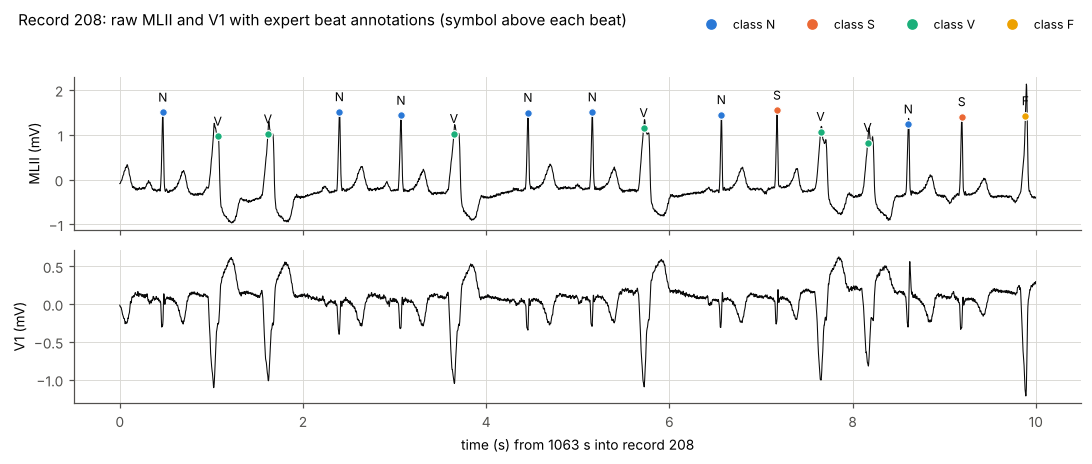

In [3]:
rec, ann = load_record(208)
fs = rec.fs
length = 10 * fs
samples = np.array(ann.sample)
symbols = np.array(ann.symbol)

# find the 10 s window with the most classes (ties broken by the number of F beats)
best_score, t0 = -1, 0
for start in range(0, rec.sig_len - length, fs):
    inside = (samples >= start) & (samples < start + length)
    classes_present = {SYMBOL_TO_CLASS[s] for s in symbols[inside] if s in SYMBOL_TO_CLASS}
    score = len(classes_present) * 1000 + (symbols[inside] == "F").sum()
    if score > best_score:
        best_score, t0 = score, start

t = np.arange(length) / fs
fig, ax = plt.subplots(2, 1, figsize=(10, 4.2), sharex=True)
for channel in range(2):
    ax[channel].plot(t, rec.p_signal[t0:t0 + length, channel], color=INK, lw=0.7)
    ax[channel].set_ylabel(f"{rec.sig_name[channel]} (mV)")

inside = (samples >= t0) & (samples < t0 + length)
for position, symbol in zip(samples[inside], symbols[inside]):
    x = (position - t0) / fs
    y = rec.p_signal[position, 0]
    color = CLASS_COLOR[CLASSES[SYMBOL_TO_CLASS[symbol]]] if symbol in SYMBOL_TO_CLASS else MUTED
    ax[0].plot(x, y, "o", ms=5, color=color, mec="white", mew=0.8)
    ax[0].annotate(symbol, (x, y), xytext=(0, 7), textcoords="offset points", ha="center", fontsize=8)

legend_markers = [plt.Line2D([], [], marker="o", ls="", color=CLASS_COLOR[c]) for c in CLASSES]
fig.legend(legend_markers, [f"class {c}" for c in CLASSES], ncol=4, loc="upper right", bbox_to_anchor=(0.99, 1.0), fontsize=8)
ax[1].set_xlabel(f"time (s) from {t0 / fs:.0f} s into record 208")
fig.suptitle("Record 208: raw MLII and V1 with expert beat annotations (symbol above each beat)", x=0.02, ha="left", y=0.99, fontsize=10)
fig.tight_layout(rect=(0, 0, 1, 0.95))
save_figure(fig, "fig_example_ecg.png")

## Figure: example heartbeat from each class (DS1)
Top row: the most typical beat of each class (the one closest to the class average), in mV.
Bottom row: the prepared model input for that class, average ± one standard deviation.

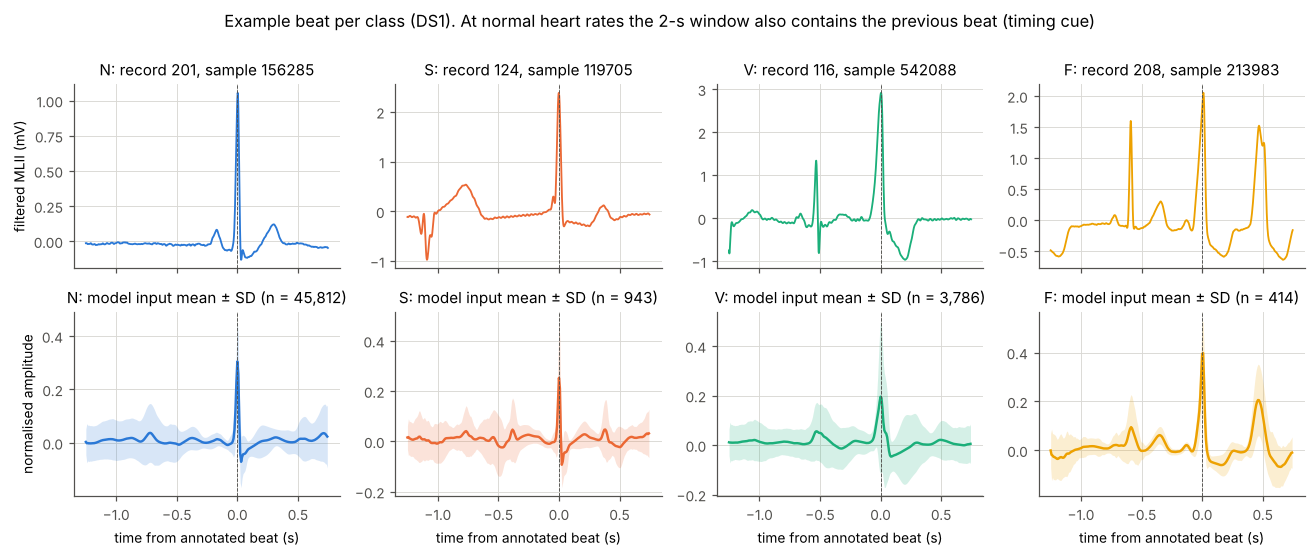

In [4]:
train = np.load(f"{cfg['paths']['processed']}/ds1_train.npz", allow_pickle=True)
val = np.load(f"{cfg['paths']['processed']}/ds1_val.npz", allow_pickle=True)
X_ds1 = np.concatenate([train["X"], val["X"]])
y_ds1 = np.concatenate([train["y"], val["y"]])
record_ds1 = np.concatenate([train["record"], val["record"]])
sample_ds1 = np.concatenate([train["sample"], val["sample"]])
rr_ds1 = np.concatenate([train["rr_ratio"], val["rr_ratio"]])

time_128 = (np.arange(256) - 160) / 128     # seconds relative to the beat (beat is at sample 160)
time_360 = (np.arange(720) - 450) / 360


def correlation_with(beats, template):
    # Pearson correlation of every row of `beats` with `template`
    b = beats - beats.mean(axis=1, keepdims=True)
    t = template - template.mean()
    return (b @ t) / (np.linalg.norm(b, axis=1) * np.linalg.norm(t) + 1e-12)


fig, ax = plt.subplots(2, 4, figsize=(12, 5), sharex=True)
for c, name in enumerate(CLASSES):
    beats = X_ds1[y_ds1 == c, 0]
    mean, std = beats.mean(axis=0), beats.std(axis=0)
    k = int(np.argmax(correlation_with(beats, mean)))
    record, position = record_ds1[y_ds1 == c][k], sample_ds1[y_ds1 == c][k]

    sig, fs, _, _, _ = read_record(MITDB, record)
    filtered = bandpass(sig, fs, 0.5, 40)
    ax[0, c].plot(time_360, filtered[position - 450:position + 270], color=CLASS_COLOR[name], lw=1.2)
    ax[0, c].set_title(f"{name}: record {record}, sample {position}")

    ax[1, c].fill_between(time_128, mean - std, mean + std, color=CLASS_COLOR[name], alpha=0.18, lw=0)
    ax[1, c].plot(time_128, mean, color=CLASS_COLOR[name], lw=1.6)
    ax[1, c].set_title(f"{name}: model input mean ± SD (n = {len(beats):,})")
    ax[1, c].set_xlabel("time from annotated beat (s)")
    for a in ax[:, c]:
        a.axvline(0, color=MUTED, lw=0.6, ls="--")

ax[0, 0].set_ylabel("filtered MLII (mV)")
ax[1, 0].set_ylabel("normalised amplitude")
fig.suptitle("Example beat per class (DS1). At normal heart rates the 2-s window also contains the previous beat (timing cue)", y=1.0)
fig.tight_layout()
save_figure(fig, "fig_class_beats.png")

## Figure: RR ratio per class (DS1)
RR ratio = time since the previous beat divided by the recent average. Below 1 means the beat came early.
This shows why the model gets a second input channel with timing information.

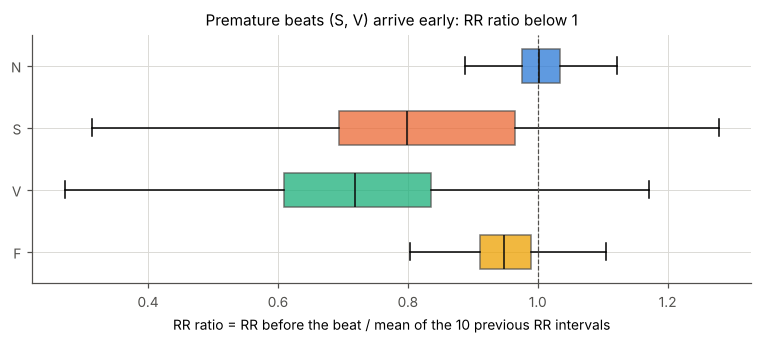

,count,mean,std,min,25%,50%,75%,max
N,45812.0,1.029,0.166,0.251,0.976,1.002,1.034,15.243
S,943.0,0.797,0.187,0.281,0.694,0.799,0.965,1.397
V,3786.0,0.762,1.603,0.097,0.610,0.719,0.835,98.869
F,414.0,0.960,0.114,0.476,0.911,0.948,0.990,2.378


In [5]:
fig, ax = plt.subplots(figsize=(7, 3.2))
boxes = ax.boxplot([rr_ds1[y_ds1 == c] for c in range(4)], orientation="horizontal", tick_labels=CLASSES,
                   showfliers=False, widths=0.55, patch_artist=True, medianprops={"color": INK})
for box, name in zip(boxes["boxes"], CLASSES):
    box.set_facecolor(CLASS_COLOR[name])
    box.set_alpha(0.75)
    box.set_edgecolor(MUTED)
ax.axvline(1, color=MUTED, ls="--", lw=0.8)
ax.set_xlabel("RR ratio = RR before the beat / mean of the 10 previous RR intervals")
ax.set_title("Premature beats (S, V) arrive early: RR ratio below 1")
ax.invert_yaxis()
fig.tight_layout()
save_figure(fig, "fig_rr_ratio.png")

rr_table = pd.DataFrame({name: pd.Series(rr_ds1[y_ds1 == c]).describe() for c, name in enumerate(CLASSES)}).T.round(3)
rr_table.to_csv(f"{RESULTS}/rr_ratio_by_class_ds1.csv")
rr_table

## Figure: class distribution
Number of beats per class in each split (log scale, so the small classes are visible).

,records,subjects,N,S,V,F,total
split,,,,,,,
train,17,17,36489,615,3052,393,40549
val,5,5,9323,328,734,21,10406
test,22,22,44208,1837,3219,388,49652


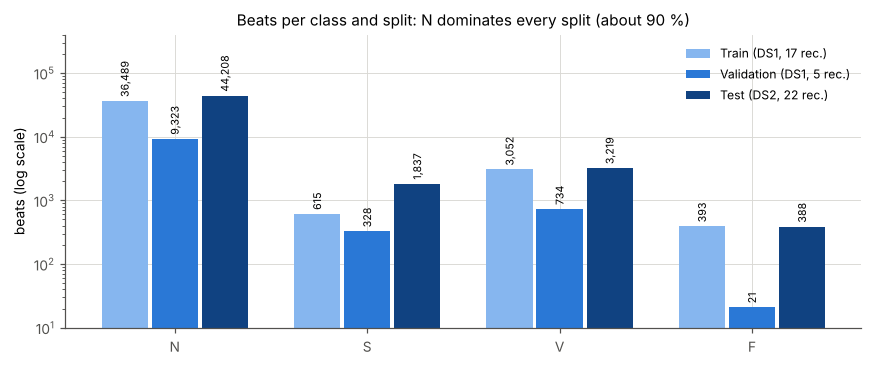

,N,S,V,F,N_percent,S_percent,V_percent,F_percent,N_per_F,S_per_F,V_per_F,F_per_F
split,,,,,,,,,,,,
train,36489,615,3052,393,89.99,1.52,7.53,0.97,92.8,1.6,7.8,1.0
val,9323,328,734,21,89.59,3.15,7.05,0.20,444.0,15.6,35.0,1.0
test,44208,1837,3219,388,89.04,3.70,6.48,0.78,113.9,4.7,8.3,1.0


In [6]:
split_stats = pd.read_csv(f"{RESULTS}/split_stats.csv").set_index("split")
display(split_stats)

split_labels = {"train": "Train (DS1, 17 rec.)", "val": "Validation (DS1, 5 rec.)", "test": "Test (DS2, 22 rec.)"}
bar_width = 0.26
fig, ax = plt.subplots(figsize=(8, 3.4))
for j, split in enumerate(["train", "val", "test"]):
    counts = split_stats.loc[split, CLASSES].values
    x = np.arange(4) + (j - 1) * bar_width
    ax.bar(x, counts, width=bar_width - 0.02, color=SPLIT_COLOR[split], label=split_labels[split])
    for xi, count in zip(x, counts):
        ax.text(xi, count * 1.15, f"{count:,}", ha="center", va="bottom", fontsize=7, rotation=90)
ax.set_yscale("log")
ax.set_ylim(10, 4e5)
ax.set_xticks(range(4), CLASSES)
ax.set_ylabel("beats (log scale)")
ax.legend(loc="upper right", fontsize=8)
ax.set_title("Beats per class and split: N dominates every split (about 90 %)")
fig.tight_layout()
save_figure(fig, "fig_class_distribution.png")

pd.read_csv(f"{RESULTS}/class_counts.csv", index_col=0)

## Figure: subject/record distribution
Beats per class in every record. Rare classes come from only a few records (patients).
The table after the figure shows how much of each class comes from the top 1 and top 3 records.

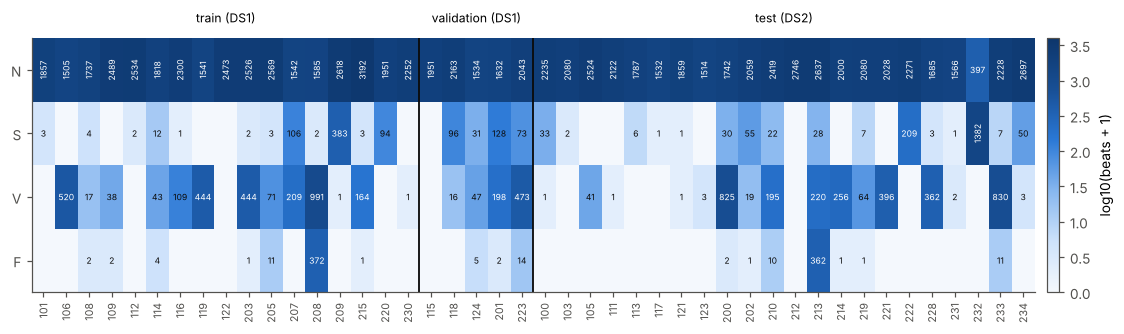

,split,cls,total,records_with_class,top1_record,top1_share,top3_share
0,train,S,615,12,209,0.623,0.948
1,train,V,3052,13,208,0.325,0.641
2,train,F,393,7,208,0.947,0.985
3,val,S,328,4,201,0.390,0.905
4,val,V,734,4,223,0.644,0.978
5,val,F,21,3,223,0.667,1.000
6,test,S,1837,16,232,0.752,0.896
7,test,V,3219,16,233,0.258,0.637
8,test,F,388,7,213,0.933,0.987


In [7]:
record_counts = pd.read_csv(f"{RESULTS}/record_class_counts.csv")
split_order = {"train": 0, "val": 1, "test": 2}
record_counts["split_order"] = record_counts.split.map(split_order)
record_counts = record_counts.sort_values(["split_order", "record"]).drop(columns="split_order").reset_index(drop=True)
matrix = record_counts[CLASSES].T.values          # 4 rows (classes) x 44 columns (records)

from matplotlib.colors import LinearSegmentedColormap
blues = LinearSegmentedColormap.from_list("blues", ["#f4f8fd", "#cde2fb", "#86b6ef", "#2a78d6", "#184f95", "#0d366b"])
fig, ax = plt.subplots(figsize=(14, 3.0))
image = ax.imshow(np.log10(matrix + 1), aspect="auto", cmap=blues, vmin=0, vmax=3.6)
for i in range(4):
    for j in range(matrix.shape[1]):
        value = matrix[i, j]
        if value > 0:
            text_color = "white" if np.log10(value + 1) > 2.2 else INK
            ax.text(j, i, str(value), ha="center", va="center", fontsize=5.6, color=text_color, rotation=90 if value >= 1000 else 0)
ax.set_xticks(range(len(record_counts)), record_counts.record.astype(str), fontsize=7, rotation=90)
ax.set_yticks(range(4), CLASSES)
ax.grid(False)

# vertical lines between the splits, and split names above
split_ends = record_counts.groupby("split", sort=False).size().reindex(["train", "val", "test"]).cumsum().values
for end in split_ends[:-1]:
    ax.axvline(end - 0.5, color=INK, lw=1.2)
for name, start, end in zip(["train (DS1)", "validation (DS1)", "test (DS2)"], [0, *split_ends[:-1]], split_ends):
    ax.text((start + end - 1) / 2, -0.75, name, ha="center", fontsize=8)
plt.colorbar(image, ax=ax, label="log10(beats + 1)", pad=0.01)
save_figure(fig, "fig_record_distribution.png")

rows = []
for split in ["train", "val", "test"]:
    part = record_counts[record_counts.split == split]
    for name in ["S", "V", "F"]:
        total = part[name].sum()
        top3 = part.sort_values(name, ascending=False).head(3)
        rows.append({"split": split, "cls": name, "total": int(total),
                     "records_with_class": int((part[name] > 0).sum()),
                     "top1_record": int(top3.record.iloc[0]),
                     "top1_share": round(top3[name].iloc[0] / total, 3),
                     "top3_share": round(top3[name].sum() / total, 3)})
concentration = pd.DataFrame(rows)
concentration.to_csv(f"{RESULTS}/class_concentration.csv", index=False)
concentration

## Figure: signal amplitude distribution
Left: all filtered MLII samples. Middle: QRS peak-to-peak amplitude per record (how tall the beats are).
Right: values of the model input after normalisation, per class.

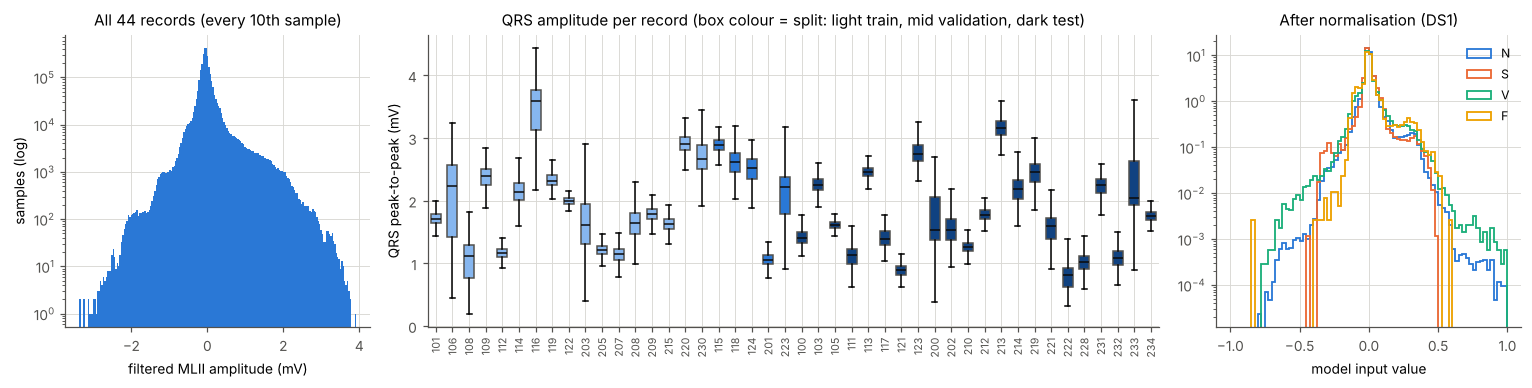

filtered amplitude percentiles (mV) 0.1/1/50/99/99.9: [-1.47 -0.69 -0.05  1.53  2.46]
median QRS peak-to-peak per record: min 0.81 mV (record 222), max 3.59 mV (record 116)


In [8]:
amplitudes = []
qrs_peak_to_peak = {}
for record in USED_RECORDS:
    sig, fs, samples, symbols, _ = read_record(MITDB, record)
    filtered = bandpass(sig, fs, 0.5, 40)
    amplitudes.append(filtered[::10])                  # every 10th sample is enough for a histogram
    w = int(0.05 * fs)                                  # +-50 ms around each beat
    qrs_peak_to_peak[record] = np.array([np.ptp(filtered[max(0, s - w):s + w + 1]) for s in beat_positions(samples, symbols)])
amplitudes = np.concatenate(amplitudes)

fig, ax = plt.subplots(1, 3, figsize=(14, 3.6), gridspec_kw={"width_ratios": [1, 2.4, 1]})
ax[0].hist(amplitudes, bins=200, color=CLASS_COLOR["N"], log=True)
ax[0].set_xlabel("filtered MLII amplitude (mV)")
ax[0].set_ylabel("samples (log)")
ax[0].set_title("All 44 records (every 10th sample)")

records_in_order = record_counts.record.tolist()
boxes = ax[1].boxplot([qrs_peak_to_peak[r] for r in records_in_order], tick_labels=[str(r) for r in records_in_order],
                      showfliers=False, widths=0.6, patch_artist=True, medianprops={"color": INK})
for box, record in zip(boxes["boxes"], records_in_order):
    box.set_facecolor(SPLIT_COLOR[SPLIT_OF[record]])
    box.set_edgecolor(MUTED)
ax[1].tick_params(axis="x", rotation=90, labelsize=7)
ax[1].set_ylabel("QRS peak-to-peak (mV)")
ax[1].set_title("QRS amplitude per record (box colour = split: light train, mid validation, dark test)")

for c, name in enumerate(CLASSES):
    ax[2].hist(X_ds1[y_ds1 == c, 0].ravel()[::7], bins=80, range=(-1, 1), density=True,
               histtype="step", color=CLASS_COLOR[name], label=name, lw=1.2)
ax[2].set_yscale("log")
ax[2].set_xlabel("model input value")
ax[2].set_title("After normalisation (DS1)")
ax[2].legend(fontsize=8)
fig.tight_layout()
save_figure(fig, "fig_amplitude.png")

amplitude_table = pd.DataFrame({r: pd.Series(v).describe() for r, v in qrs_peak_to_peak.items()}).T.round(3)
amplitude_table.insert(0, "split", [SPLIT_OF[r] for r in amplitude_table.index])
amplitude_table.to_csv(f"{RESULTS}/qrs_amplitude_by_record.csv")
print("filtered amplitude percentiles (mV) 0.1/1/50/99/99.9:", np.percentile(amplitudes, [0.1, 1, 50, 99, 99.9]).round(2))
median_pp = amplitude_table["50%"]
print(f"median QRS peak-to-peak per record: min {median_pp.min():.2f} mV (record {median_pp.idxmin()}), "
      f"max {median_pp.max():.2f} mV (record {median_pp.idxmax()})")

## Figure: examples of noisy ECG
Real noise from the Noise Stress Test Database (only the half reserved for testing) is added to the clean
DS1 record 122 at 12, 6 and 0 dB. The table after the figure checks that the added noise has exactly the requested SNR.

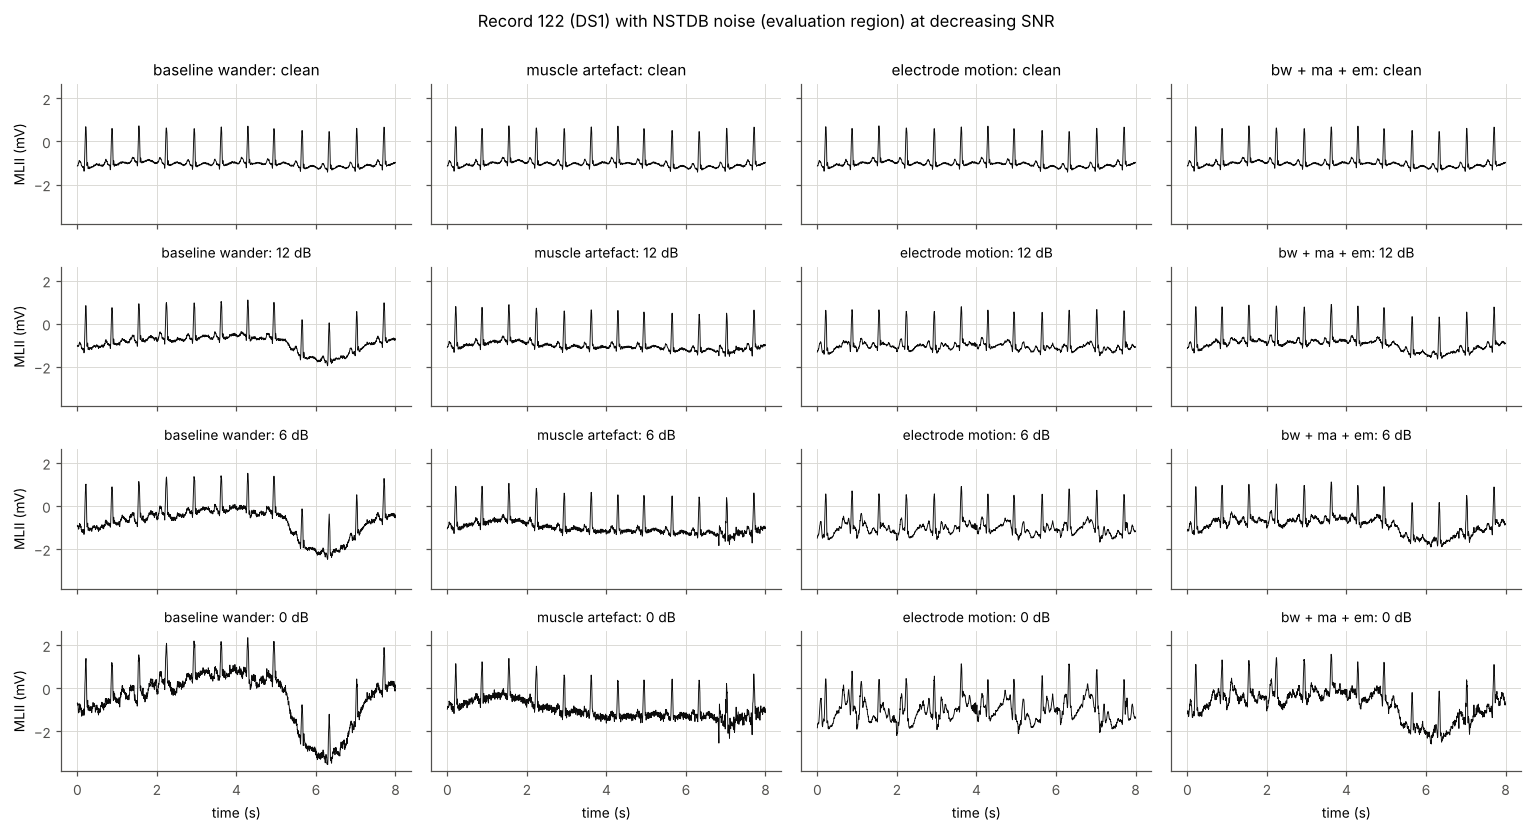

target_snr_db,0,6,12
noise,,,
bw,0.0,6.0,12.0
em,-0.0,6.0,12.0
ma,0.0,6.0,12.0
mix,0.0,6.0,12.0


In [9]:
sig, fs, samples, symbols, _ = read_record(MITDB, 122)
beats = beat_positions(samples, symbols)
length = 8 * fs
t0 = 60 * fs                     # show seconds 60-68 of the record
t = np.arange(length) / fs
noise_names = {"bw": "baseline wander", "ma": "muscle artefact", "em": "electrode motion", "mix": "bw + ma + em"}

fig, ax = plt.subplots(4, 4, figsize=(14, 7.5), sharex=True, sharey=True)
snr_check = []
for j, kind in enumerate(noise_names):
    noise = load_noise(NSTDB, kind, noise_cfg["noise_channel"], noise_cfg["eval_region"])
    ax[0, j].plot(t, sig[t0:t0 + length], color=INK, lw=0.6)
    ax[0, j].set_title(f"{noise_names[kind]}: clean")
    for i, snr in enumerate(noise_cfg["snr_db"], start=1):
        rng = np.random.default_rng(noise_cfg["noise_seed"])
        noisy = add_noise(sig, beats, noise, snr, fs, rng)
        ax[i, j].plot(t, noisy[t0:t0 + length], color=INK, lw=0.6)
        ax[i, j].set_title(f"{noise_names[kind]}: {snr} dB", fontsize=9)
        measured = 10 * np.log10(signal_power(sig, beats, fs) / noise_power(noisy - sig, fs))
        snr_check.append({"noise": kind, "target_snr_db": snr, "measured_snr_db": round(measured, 2)})
for a in ax[:, 0]:
    a.set_ylabel("MLII (mV)")
for a in ax[-1]:
    a.set_xlabel("time (s)")
fig.suptitle("Record 122 (DS1) with NSTDB noise (evaluation region) at decreasing SNR", y=1.0)
fig.tight_layout()
save_figure(fig, "fig_noise_examples.png")

pd.DataFrame(snr_check).pivot(index="noise", columns="target_snr_db", values="measured_snr_db")

A real noisy stretch: the longest interval in DS1 record 203 that the experts marked as noisy.

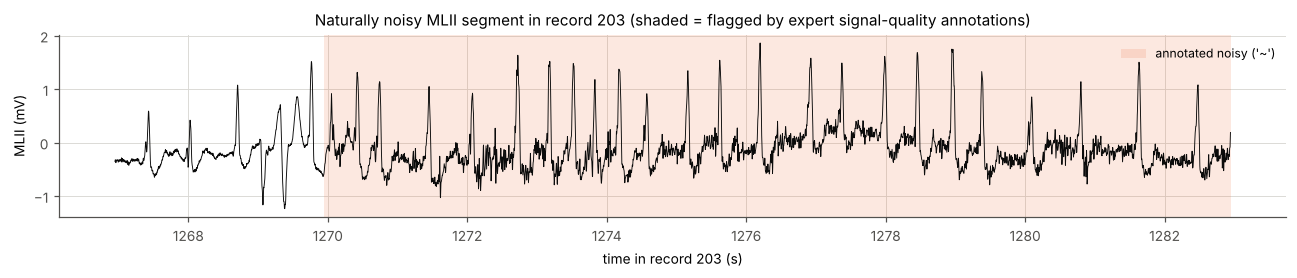

In [10]:
intervals = noisy_intervals(203)
start, end, _ = max(intervals, key=lambda interval: interval[1] - interval[0])
rec, _ = load_record(203)
fs = rec.fs
first = max(0, start - 3 * fs)                    # 3 s of clean signal before the noisy part
last = min(rec.sig_len, first + 16 * fs)

fig, ax = plt.subplots(figsize=(12, 2.6))
ax.plot(np.arange(first, last) / fs, rec.p_signal[first:last, 0], color=INK, lw=0.6)
ax.axvspan(start / fs, min(end, last) / fs, color=CLASS_COLOR["S"], alpha=0.15, lw=0, label="annotated noisy ('~')")
ax.set_xlabel("time in record 203 (s)")
ax.set_ylabel("MLII (mV)")
ax.legend(loc="upper right", fontsize=8)
ax.set_title("Naturally noisy MLII segment in record 203 (shaded = flagged by expert signal-quality annotations)")
fig.tight_layout()
save_figure(fig, "fig_noise_natural.png")

### Why we changed the SNR definition (DS1 only)
The first draft measured signal power as the average power of the whole filtered ECG. The NSTDB convention
uses the QRS amplitude instead. This table shows, for each DS1 record, how much weaker the draft's noise was
at the same nominal SNR.

In [11]:
rows = []
for record in DS1_RECORDS:
    sig, fs, samples, symbols, _ = read_record(MITDB, record)
    beats = beat_positions(samples, symbols)
    s_nst = signal_power(sig, beats, fs)
    p_draft = np.mean(bandpass(sig, fs, 0.5, 40) ** 2)
    rows.append({"record": record, "split": SPLIT_OF[record], "S_nst_mV2": round(s_nst, 4),
                 "P_draft_mV2": round(p_draft, 4),
                 "draft_noise_weaker_by_dB": round(10 * np.log10(s_nst / p_draft), 2)})
snr_definition = pd.DataFrame(rows)
snr_definition.to_csv(f"{RESULTS}/snr_definition_check_ds1.csv", index=False)
print(snr_definition.draft_noise_weaker_by_dB.describe().round(2))

count    22.00
mean      7.12
std       2.43
min       2.78
25%       5.85
50%       7.19
75%       8.17
max      11.66
Name: draft_noise_weaker_by_dB, dtype: float64


## 2.4 Data quality
For the MLII lead of every used record we check:
- missing values and flat lines (the same value for 0.5 s or longer),
- saturation (the recorder's limit, digital value 0 or 2047) and values above 5 mV,
- how long the experts marked the signal as noisy,
- a simple quality index: how similar each normal beat is to the record's typical beat (correlation below 0.8 = low quality),
- QRS amplitude and heart rate, and how similar the second lead is to MLII.

In [12]:
rows = []
for record in USED_RECORDS:
    rec, ann = load_record(record)
    fs = rec.fs
    mlii = rec.sig_name.index("MLII")
    x = rec.p_signal[:, mlii]
    digital = wfdb.rdrecord(f"{MITDB}/{record}", physical=False).d_signal[:, mlii]
    max_code = 2 ** rec.adc_res[mlii] - 1
    saturated = (digital <= 0) | (digital >= max_code)

    # count runs of identical samples that last at least 0.5 s
    repeated = np.r_[False, np.diff(digital) == 0]
    flat_runs, run_length = 0, 0
    for same in repeated:
        run_length = run_length + 1 if same else 0
        if run_length == int(0.5 * fs):
            flat_runs += 1

    intervals = noisy_intervals(record)
    noisy_seconds = sum(end - start for start, end, _ in intervals) / fs
    unreadable_seconds = sum(end - start for start, end, kind in intervals if kind == "unreadable") / fs

    # quality index on normal-shaped beats (N, L, R), +-0.25 s around each beat
    symbols = np.array(ann.symbol)
    samples = np.array(ann.sample)
    filtered = bandpass(x, fs, 0.5, 40)
    w = int(0.25 * fs)
    normal = samples[np.isin(symbols, ["N", "L", "R"])]
    normal = normal[(normal > w) & (normal < len(filtered) - w)]
    normal_beats = np.stack([filtered[s - w:s + w] for s in normal])
    similarity = correlation_with(normal_beats, np.median(normal_beats, axis=0))

    rr_seconds = np.diff(beat_positions(samples, symbols)) / fs
    other_lead = bandpass(rec.p_signal[:, 1 - mlii], fs, 0.5, 40)
    rows.append({
        "record": record,
        "split": SPLIT_OF[record],
        "nan_samples": int(np.isnan(x).sum()),
        "saturated_samples": int(saturated.sum()),
        "flat_runs_ge_0p5s": flat_runs,
        "abs_gt_5mV": int((np.abs(x) > 5).sum()),
        "noisy_annotated_s": round(noisy_seconds, 1),
        "noisy_annotated_pct": round(100 * noisy_seconds / (len(x) / fs), 2),
        "unreadable_s": round(unreadable_seconds, 1),
        "artefact_annotations": int((symbols == "|").sum()),
        "normal_beats_low_sqi_pct": round(100 * (similarity < 0.8).mean(), 2),
        "median_qrs_pp_mV": round(float(np.median(qrs_peak_to_peak[record])), 3),
        "mean_hr_bpm": round(60 / rr_seconds.mean(), 1),
        "rr_cv": round(rr_seconds.std() / rr_seconds.mean(), 3),
        "other_lead": rec.sig_name[1 - mlii],
        "corr_mlii_other": round(float(np.corrcoef(filtered, other_lead)[0, 1]), 3),
    })
quality = pd.DataFrame(rows)
quality.to_csv(f"{RESULTS}/data_quality.csv", index=False)
pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 30)
quality

,record,split,nan_samples,saturated_samples,flat_runs_ge_0p5s,abs_gt_5mV,noisy_annotated_s,noisy_annotated_pct,unreadable_s,artefact_annotations,normal_beats_low_sqi_pct,median_qrs_pp_mV,mean_hr_bpm,rr_cv,other_lead,corr_mlii_other
0,100,test,0,0,0,0,0.0,0.00,0.0,0,0.00,1.414,75.5,0.061,V5,0.714
1,101,train,0,0,0,0,4.7,0.26,1.0,4,0.22,1.714,62.0,0.073,V1,-0.330
2,103,test,0,0,0,0,8.7,0.48,0.0,0,0.05,2.252,69.3,0.054,V2,0.469
3,105,test,0,0,0,0,260.6,14.43,131.4,30,8.23,1.613,85.5,0.092,V1,-0.425
4,106,train,0,0,0,0,0.0,0.00,0.0,0,0.13,2.242,67.4,0.293,V1,0.138
5,108,train,0,0,0,0,196.1,10.86,0.0,8,50.86,1.125,58.6,0.121,V1,-0.359
6,109,train,0,0,0,0,0.0,0.00,0.0,0,0.36,2.390,84.1,0.053,V1,-0.793
7,111,test,0,0,0,0,7.2,0.40,0.0,0,5.75,1.130,70.6,0.045,V1,-0.479
8,112,train,0,0,0,0,21.0,1.17,0.0,0,0.04,1.164,84.4,0.031,V1,-0.285
9,113,test,0,0,0,0,0.0,0.00,0.0,0,0.00,2.462,59.6,0.099,V1,-0.543


In [13]:
quality_summary = {
    "records with NaN samples": int((quality.nan_samples > 0).sum()),
    "records with ADC-saturated MLII samples": quality.loc[quality.saturated_samples > 0, ["record", "saturated_samples"]].values.tolist(),
    "records with flat-line runs >= 0.5 s": quality.loc[quality.flat_runs_ge_0p5s > 0, ["record", "flat_runs_ge_0p5s"]].values.tolist(),
    "total annotated noisy MLII time (min)": round(quality.noisy_annotated_s.sum() / 60, 1),
    "total unreadable time (min)": round(quality.unreadable_s.sum() / 60, 1),
    "top-5 annotated noisy records (% of record)": quality.nlargest(5, "noisy_annotated_pct")[["record", "noisy_annotated_pct"]].values.tolist(),
    "top-5 low-SQI records (% normal beats with template corr < 0.8)": quality.nlargest(5, "normal_beats_low_sqi_pct")[["record", "normal_beats_low_sqi_pct"]].values.tolist(),
    "Spearman corr(annotated noisy %, low-SQI %)": round(quality[["noisy_annotated_pct", "normal_beats_low_sqi_pct"]].corr("spearman").iloc[0, 1], 2),
    "median QRS pp range (mV)": [quality.median_qrs_pp_mV.min(), quality.median_qrs_pp_mV.max()],
    "mean heart rate range (bpm)": [quality.mean_hr_bpm.min(), quality.mean_hr_bpm.max()],
    "other-lead names": quality.other_lead.value_counts().to_dict(),
    "MLII vs other lead correlation range": [quality.corr_mlii_other.min(), quality.corr_mlii_other.max()],
}
with open(f"{RESULTS}/data_quality_summary.json", "w") as f:
    json.dump(quality_summary, f, indent=2, default=str)
for key, value in quality_summary.items():
    print(f"{key:62s} {value}")

records with NaN samples                                       0
records with ADC-saturated MLII samples                        [[116, 928]]
records with flat-line runs >= 0.5 s                           [[116, 3]]
total annotated noisy MLII time (min)                          23.1
total unreadable time (min)                                    2.8
top-5 annotated noisy records (% of record)                    [[105.0, 14.43], [203.0, 12.66], [108.0, 10.86], [232.0, 7.38], [200.0, 5.86]]
top-5 low-SQI records (% normal beats with template corr < 0.8) [[108.0, 50.86], [222.0, 30.52], [117.0, 30.4], [203.0, 15.9], [105.0, 8.23]]
Spearman corr(annotated noisy %, low-SQI %)                    0.62
median QRS pp range (mV)                                       [np.float64(0.808), np.float64(3.588)]
mean heart rate range (bpm)                                    [np.float64(50.4), np.float64(111.8)]
other-lead names                                               {'V1': 38, 'V5': 3, 'V2': 2, 'V4

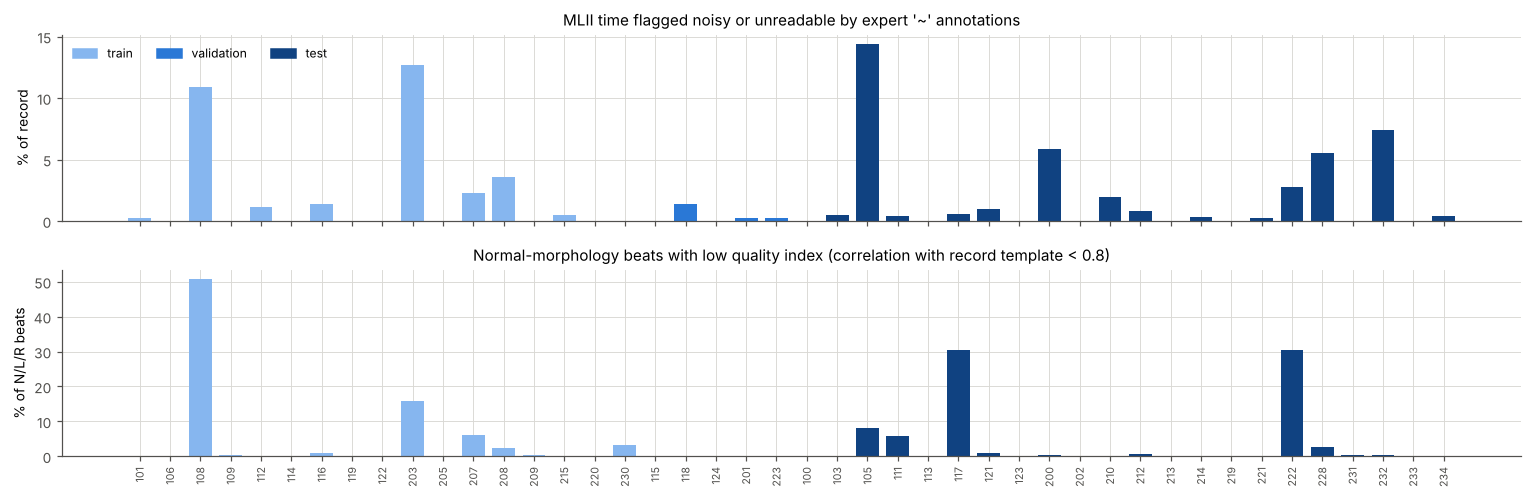

In [14]:
by_record = quality.set_index("record").loc[record_counts.record]
x = np.arange(len(by_record))
colors = [SPLIT_COLOR[s] for s in by_record.split]

fig, ax = plt.subplots(2, 1, figsize=(14, 4.6), sharex=True)
ax[0].bar(x, by_record.noisy_annotated_pct, color=colors, width=0.75)
ax[0].set_ylabel("% of record")
ax[0].set_title("MLII time flagged noisy or unreadable by expert '~' annotations")
ax[1].bar(x, by_record.normal_beats_low_sqi_pct, color=colors, width=0.75)
ax[1].set_ylabel("% of N/L/R beats")
ax[1].set_title("Normal-morphology beats with low quality index (correlation with record template < 0.8)")
ax[1].set_xticks(x, by_record.index.astype(str), rotation=90, fontsize=7)
legend_patches = [plt.Rectangle((0, 0), 1, 1, color=SPLIT_COLOR[s]) for s in SPLIT_COLOR]
ax[0].legend(legend_patches, ["train", "validation", "test"], ncol=3, loc="upper left", fontsize=8)
fig.tight_layout()
save_figure(fig, "fig_data_quality.png")

## Figure: differences between ECG channels
Three seconds of both channels for four records. Channel 0 is always MLII here; channel 1 is a different lead in each record.

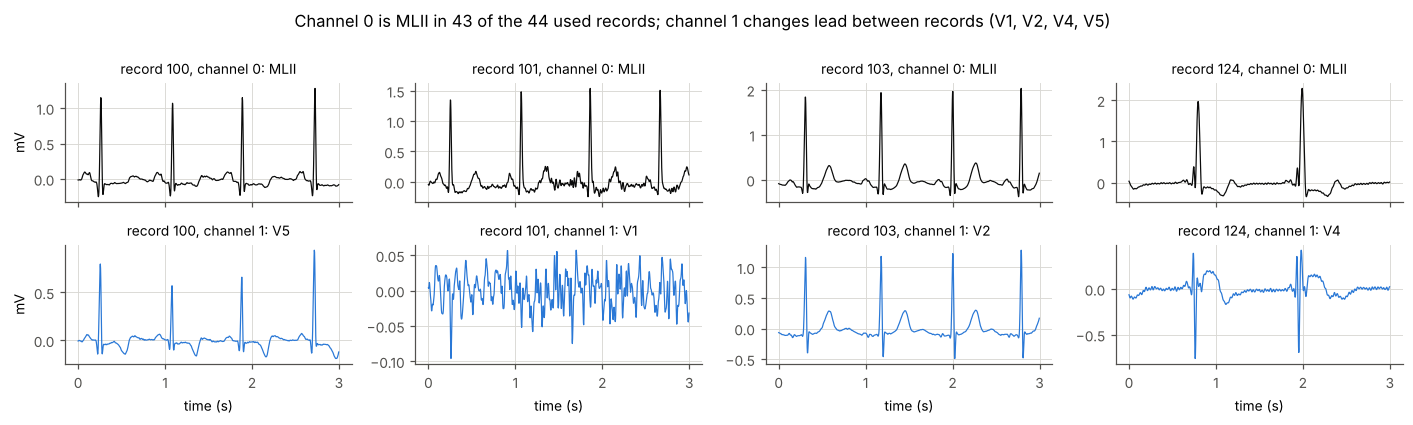

In [15]:
fig, ax = plt.subplots(2, 4, figsize=(13, 3.8), sharex=True)
for j, record in enumerate([100, 101, 103, 124]):
    rec, _ = load_record(record)
    fs = rec.fs
    window = slice(30 * fs, 33 * fs)
    t = np.arange(3 * fs) / fs
    for channel in range(2):
        color = INK if rec.sig_name[channel] == "MLII" else CLASS_COLOR["N"]
        ax[channel, j].plot(t, bandpass(rec.p_signal[:, channel], fs, 0.5, 40)[window], color=color, lw=0.8)
        ax[channel, j].set_title(f"record {record}, channel {channel}: {rec.sig_name[channel]}", fontsize=9)
    ax[1, j].set_xlabel("time (s)")
ax[0, 0].set_ylabel("mV")
ax[1, 0].set_ylabel("mV")
fig.suptitle("Channel 0 is MLII in 43 of the 44 used records; channel 1 changes lead between records (V1, V2, V4, V5)", y=1.0)
fig.tight_layout()
save_figure(fig, "fig_channels.png")

## 2.5 Leakage experiment (DS1 only)
We train the same simple classifier (1-nearest neighbour) twice:
1. beats split **at random** into 80 % training / 20 % evaluation (beats of one patient end up on both sides),
2. beats split **by record**: 17 training records against the 5 validation records.

If the random split scores much higher, the classifier is recognising patients rather than heartbeat types.

In [16]:
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier

# features: every 4th ECG sample (64 values) plus the RR value
features = np.concatenate([X_ds1[:, 0, ::4], X_ds1[:, 1, :1]], axis=1)
labels = [0, 1, 2, 3]


def evaluate_split(name, train_idx, eval_idx):
    knn = KNeighborsClassifier(n_neighbors=1, algorithm="brute", n_jobs=-1)
    knn.fit(features[train_idx], y_ds1[train_idx])
    _, nearest = knn.kneighbors(features[eval_idx], n_neighbors=1)
    nearest = nearest[:, 0]
    predicted = y_ds1[train_idx][nearest]
    truth = y_ds1[eval_idx]
    row = {
        "protocol": name,
        "train_beats": len(train_idx),
        "eval_beats": len(eval_idx),
        "accuracy": accuracy_score(truth, predicted),
        "macro_f1": f1_score(truth, predicted, average="macro", labels=labels, zero_division=0),
        # how often the closest training beat comes from the same patient record
        "nn_from_same_record": (record_ds1[train_idx][nearest] == record_ds1[eval_idx]).mean(),
    }
    recalls = recall_score(truth, predicted, labels=labels, average=None, zero_division=0)
    precisions = precision_score(truth, predicted, labels=labels, average=None, zero_division=0)
    for c, name in enumerate(CLASSES):
        row[f"{name}_recall"] = recalls[c]
    for c, name in enumerate(CLASSES):
        row[f"{name}_precision"] = precisions[c]
    return row


all_idx = np.arange(len(y_ds1))
random_train, random_eval = train_test_split(all_idx, test_size=0.2, stratify=y_ds1, random_state=cfg["seed"])
record_train = np.where(np.isin(record_ds1, cfg["records"]["train"]))[0]
record_eval = np.where(np.isin(record_ds1, cfg["records"]["val"]))[0]

leakage = pd.DataFrame([
    evaluate_split("random beat split (leaky)", random_train, random_eval),
    evaluate_split("record split (train -> validation records)", record_train, record_eval),
]).round(3)
leakage.to_csv(f"{RESULTS}/leakage_experiment.csv", index=False)
leakage.T

,0,1
protocol,random beat split (leaky),record split (train -> validation records)
train_beats,40764,40549
eval_beats,10191,10406
accuracy,0.987,0.923
macro_f1,0.875,0.492
nn_from_same_record,0.965,0.0
N_recall,0.995,0.983
S_recall,0.82,0.381
V_recall,0.966,0.425
F_recall,0.663,0.048


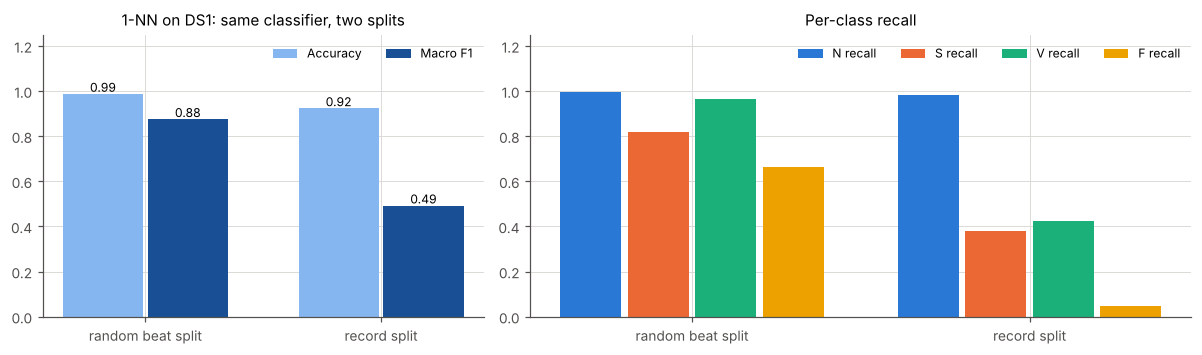

In [17]:
split_names = ["random beat split", "record split"]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.3), gridspec_kw={"width_ratios": [1, 1.5]})
for i, (column, label) in enumerate([("accuracy", "Accuracy"), ("macro_f1", "Macro F1")]):
    x = np.arange(2) + (i - 0.5) * 0.36
    ax[0].bar(x, leakage[column], width=0.34, color=["#86b6ef", "#184f95"][i], label=label)
    for xi, value in zip(x, leakage[column]):
        ax[0].text(xi, value + 0.01, f"{value:.2f}", ha="center", fontsize=8)
ax[0].set_xticks(range(2), split_names)
ax[0].set_ylim(0, 1.25)
ax[0].legend(fontsize=8, loc="upper right", ncol=2)
ax[0].set_title("1-NN on DS1: same classifier, two splits")

for c, name in enumerate(CLASSES):
    ax[1].bar(np.arange(2) + (c - 1.5) * 0.2, leakage[f"{name}_recall"], width=0.18, color=CLASS_COLOR[name], label=f"{name} recall")
ax[1].set_xticks(range(2), split_names)
ax[1].set_ylim(0, 1.25)
ax[1].legend(ncol=4, fontsize=8, loc="upper right")
ax[1].set_title("Per-class recall")
fig.tight_layout()
save_figure(fig, "fig_leakage.png")

## 3.4 Choosing the amplitude normalisation (DS1 only)
Each beat window is divided by `scale_factor × reference`, where the reference is the record's typical beat height.
If the factor is too small, tall V beats hit the clipping limit and lose their shape; if it is too large,
normal beats use only a few of the 8-bit levels. We compare the draft setting (factor 2, value at the
annotation) with the QRS peak within ±50 ms and different factors.

In [18]:
from scipy.signal import resample_poly

windows_per_record = {}
for record in DS1_RECORDS:
    sig, fs, samples, symbols, _ = read_record(MITDB, record)
    filtered = bandpass(sig, fs, 0.5, 40)
    is_beat = np.isin(symbols, list(BEAT_SYMBOLS))
    beat_samples, beat_symbols = samples[is_beat], symbols[is_beat]
    reference_draft = np.median(np.abs(filtered[beat_samples])) + 1e-6
    reference_peak = amplitude_reference(filtered, beat_samples, fs, 50)

    windows, classes = [], []
    for i, (position, symbol) in enumerate(zip(beat_samples, beat_symbols)):
        if symbol in SYMBOL_TO_CLASS and i > 0 and position - 450 >= 0 and position + 270 <= len(filtered):
            window = resample_poly(filtered[position - 450:position + 270], 16, 45)[:256]
            windows.append(window - np.median(window))
            classes.append(SYMBOL_TO_CLASS[symbol])
    windows_per_record[record] = (np.array(windows), np.array(classes), reference_draft, reference_peak)

rows = []
for reference_name, use_peak in [("|ECG| at annotation (draft)", False), ("QRS peak within +-50 ms (final)", True)]:
    for factor in [2.0, 2.5, 3.0, 4.0]:
        clipped_v, clipped_all, normal_peaks = [], [], []
        worst_share, worst_record = 0.0, None
        for record, (windows, classes, reference_draft, reference_peak) in windows_per_record.items():
            reference = reference_peak if use_peak else reference_draft
            scaled = windows / (factor * reference)
            clipped = (np.abs(scaled) >= 0.99).any(axis=1)
            clipped_v.append(clipped[classes == 2])
            clipped_all.append(clipped)
            if (classes == 2).sum() >= 20 and clipped[classes == 2].mean() > worst_share:
                worst_share, worst_record = clipped[classes == 2].mean(), record
            if (classes == 0).any():
                normal_peaks.append(np.median(np.abs(scaled[classes == 0][:, 155:166]).max(axis=1)))
        median_peak = float(np.median(normal_peaks))
        rows.append({"reference": reference_name, "scale_factor": factor,
                     "V_beats_clipped_pct": round(100 * np.concatenate(clipped_v).mean(), 2),
                     "all_beats_clipped_pct": round(100 * np.concatenate(clipped_all).mean(), 2),
                     "worst_record": worst_record, "worst_record_V_clipped_pct": round(100 * worst_share, 1),
                     "median_N_peak": round(median_peak, 3), "N_peak_int8_levels": int(round(128 * median_peak))})
normalization_choice = pd.DataFrame(rows)
normalization_choice.to_csv(f"{RESULTS}/normalization_choice_ds1.csv", index=False)
normalization_choice

,reference,scale_factor,V_beats_clipped_pct,all_beats_clipped_pct,worst_record,worst_record_V_clipped_pct,median_N_peak,N_peak_int8_levels
0,|ECG| at annotation (draft),2.0,4.28,1.02,215.0,83.5,0.517,66
1,|ECG| at annotation (draft),2.5,2.32,0.55,215.0,51.8,0.414,53
2,|ECG| at annotation (draft),3.0,0.18,0.04,215.0,3.7,0.345,44
3,|ECG| at annotation (draft),4.0,0.00,0.00,NaN,0.0,0.259,33
4,QRS peak within +-50 ms (final),2.0,4.07,0.98,215.0,80.5,0.509,65
5,QRS peak within +-50 ms (final),2.5,2.09,0.50,215.0,46.3,0.407,52
6,QRS peak within +-50 ms (final),3.0,0.03,0.01,NaN,0.0,0.340,43
7,QRS peak within +-50 ms (final),4.0,0.00,0.00,NaN,0.0,0.255,33


## 3.4 One beat through the preprocessing steps
A V beat from record 208 (DS1), from the raw signal to the final 2 × 256 model input.

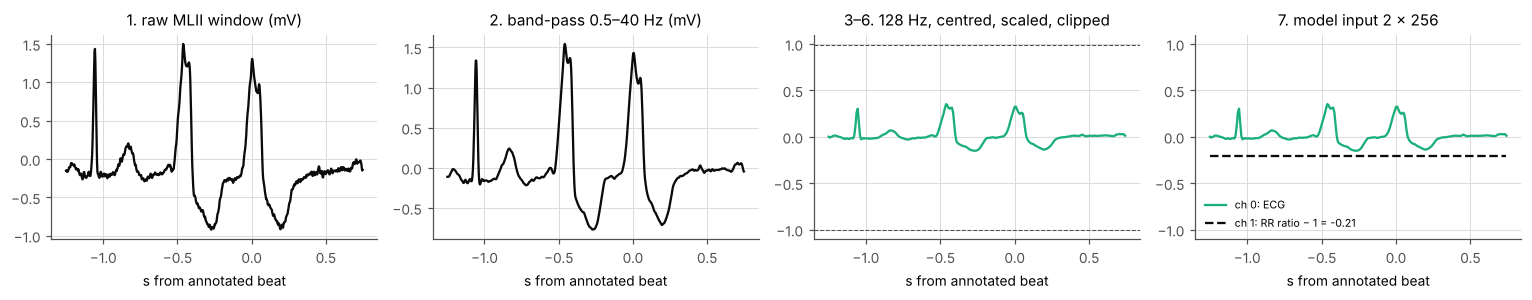

record 208, sample 28013 symbol V a_rec 1.529 mV


In [19]:
sig, fs, samples, symbols, _ = read_record(MITDB, 208)
X_208, y_208, info_208 = process_signal(sig, fs, samples, symbols, cfg)
k = np.where(y_208 == 2)[0][40]          # the 41st V beat of the record
position = info_208["sample"][k]
filtered = bandpass(sig, fs, 0.5, 40)

fig, ax = plt.subplots(1, 4, figsize=(14, 2.8))
ax[0].plot(time_360, sig[position - 450:position + 270], color=INK)
ax[0].set_title("1. raw MLII window (mV)")
ax[1].plot(time_360, filtered[position - 450:position + 270], color=INK)
ax[1].set_title("2. band-pass 0.5–40 Hz (mV)")
ax[2].plot(time_128, X_208[k, 0], color=CLASS_COLOR["V"])
ax[2].axhline(127 / 128, color=MUTED, ls="--", lw=0.7)
ax[2].axhline(-1, color=MUTED, ls="--", lw=0.7)
ax[2].set_ylim(-1.1, 1.1)
ax[2].set_title("3–6. 128 Hz, centred, scaled, clipped")
ax[3].plot(time_128, X_208[k, 0], color=CLASS_COLOR["V"], label="ch 0: ECG")
ax[3].plot(time_128, X_208[k, 1], color=INK, ls="--", label=f"ch 1: RR ratio − 1 = {X_208[k, 1, 0]:.2f}")
ax[3].set_ylim(-1.1, 1.1)
ax[3].legend(fontsize=7, loc="lower left")
ax[3].set_title("7. model input 2 × 256")
for a in ax:
    a.set_xlabel("s from annotated beat")
fig.tight_layout()
save_figure(fig, "fig_preprocessing_steps.png")
print("record 208, sample", position, "symbol", info_208["symbol"][k], "a_rec", round(info_208["a_rec"], 3), "mV")

## 3.7 Augmentation examples
Each augmentation from `src/dataset.py` at its strongest setting, applied to one training beat (grey = original).

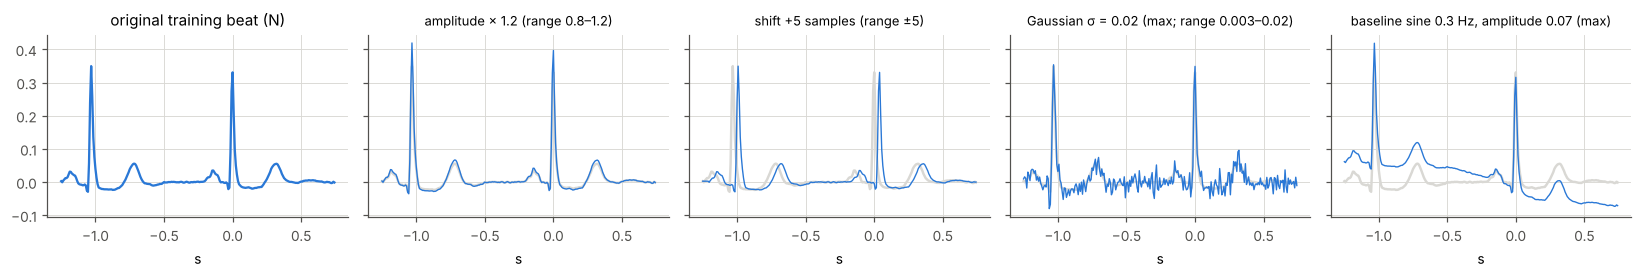

In [20]:
beat = train["X"][np.where(train["y"] == 0)[0][500], 0].astype(float)
examples = [
    ("amplitude × 1.2 (range 0.8–1.2)", scale_amplitude(beat, 1.2)),
    ("shift +5 samples (range ±5)", shift_in_time(beat, 5)),
    ("Gaussian σ = 0.02 (max; range 0.003–0.02)", add_gaussian_noise(beat, 0.02, np.random.default_rng(1))),
    ("baseline sine 0.3 Hz, amplitude 0.07 (max)", add_baseline_wander(beat, 0.07, 0.3, 1.0)),
]

fig, ax = plt.subplots(1, 5, figsize=(15, 2.6), sharey=True)
ax[0].plot(time_128, beat, color=CLASS_COLOR["N"])
ax[0].set_title("original training beat (N)")
for i, (title, augmented) in enumerate(examples, start=1):
    ax[i].plot(time_128, beat, color=GRID, lw=1.6)
    ax[i].plot(time_128, np.clip(augmented, -1, 127 / 128), color=CLASS_COLOR["N"], lw=0.9)
    ax[i].set_title(title, fontsize=8.5)
for a in ax:
    a.set_xlabel("s")
fig.tight_layout()
save_figure(fig, "fig_augmentation.png")

## 3.6 and 3.8 Final dataset and class imbalance
Tables written by `src/prepare_data.py`.

In [21]:
display(pd.read_csv(f"{RESULTS}/split_stats.csv"))
display(pd.read_csv(f"{RESULTS}/class_counts.csv"))
display(pd.read_csv(f"{RESULTS}/class_weights.csv"))
display(pd.read_csv(f"{RESULTS}/exclusions.csv"))
symbol_counts = pd.read_csv(f"{RESULTS}/symbol_counts.csv")
display(symbol_counts.pivot_table(index=["class", "symbol"], columns="split", values="count", fill_value=0)[["train", "val", "test"]])
normalization = pd.read_csv(f"{RESULTS}/record_normalization.csv")
normalization[normalization.beats_with_clipping > 0]

,split,records,subjects,N,S,V,F,total
0,train,17,17,36489,615,3052,393,40549
1,val,5,5,9323,328,734,21,10406
2,test,22,22,44208,1837,3219,388,49652


,split,N,S,V,F,N_percent,S_percent,V_percent,F_percent,N_per_F,S_per_F,V_per_F,F_per_F
0,train,36489,615,3052,393,89.99,1.52,7.53,0.97,92.8,1.6,7.8,1.0
1,val,9323,328,734,21,89.59,3.15,7.05,0.20,444.0,15.6,35.0,1.0
2,test,44208,1837,3219,388,89.04,3.70,6.48,0.78,113.9,4.7,8.3,1.0


,class,train_count,weight
0,N,36489,0.1835
1,S,615,1.4136
2,V,3052,0.6346
3,F,393,1.7683


,reason,train,val,test
0,AAMI Q-class beat 'Q',8,0,7
1,first beat (no RR interval),0,0,1
2,non-beat annotation '!',472,0,0
3,"non-beat annotation '""'",2,0,435
4,non-beat annotation '+',538,78,557
5,non-beat annotation '[',6,0,0
6,non-beat annotation ']',6,0,0
7,non-beat annotation 'x',11,47,135
8,non-beat annotation '|',60,6,65
9,non-beat annotation '~',259,30,284


split           train     val     test
class symbol                          
F     F         393.0    21.0    388.0
N     L        3946.0     0.0   4122.0
      N       32457.0  5600.0  36401.0
      R          85.0  3692.0   3472.0
      e           0.0    16.0      0.0
      j           1.0    15.0    213.0
S     A         609.0   200.0   1736.0
      J           2.0    30.0     51.0
      S           2.0     0.0      0.0
      a           2.0    98.0     50.0
V     E         105.0     0.0      1.0
      V        2947.0   734.0   3218.0

,split,record,mlii_channel,a_rec_mV,beats,beats_with_clipping,V_beats_with_clipping
2,train,108,0,0.6569,1760,3,1
14,train,215,0,0.9179,3360,2,0
39,test,228,0,0.7781,2050,371,157
